# Mini Project: Evaluating Clustering Before and After PCA
In this project we apply K-Means on the Wine dataset before and after PCA, and compare the results.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from sklearn.metrics import silhouette_score

### 1. Loading, Splitting, and Scaling the Wine Dataset
In this section, we will load the Wine dataset and verify its integrity by checking for any missing values. Following that, we will split the dataset into training and testing sets to prevent any data leakage. Finally, we will apply feature scaling using standardization (scaling features to have a mean of 0 and a standard deviation of 1).

In [2]:
# Load the Wine dataset from sklearn
data = load_wine()

# Extract the feature matrix (X) and target labels (y)
X = data.data
y = data.target

In [3]:
# Create a DataFrame to easily check for missing values
df_check = pd.DataFrame(X, columns=data.feature_names)

# Check for missing values in each column
missing_values = df_check.isnull().sum()
print("Missing values per column:")
print(missing_values)

# Check if there are any missing values in the entire dataset
total_missing = df_check.isnull().sum().sum()
print(f"\nTotal missing values: {total_missing}")

Missing values per column:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Total missing values: 0


In [4]:
# Split the dataset into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [5]:
# Initialize the standard scaler
scaler = StandardScaler()

# Learn the scaling parameters from training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform the test data using the training parameters to prevent data leakage
X_test_scaled = scaler.transform(X_test)

### 2. K-Means Before PCA
We apply K-Means on the original scaled data (13 features). We use $K=3$ because the dataset has 3 classes of wine.

In [6]:
# Apply K-Means on the original scaled training data (Before PCA)
kmeans_before = KMeans(n_clusters=3, random_state=42)
train_labels_before = kmeans_before.fit_predict(X_train_scaled)

# Evaluate clustering using silhouette score
sil_score_before = silhouette_score(X_train_scaled, train_labels_before)
print(f"Silhouette Score before PCA: {sil_score_before:.4f}")

Silhouette Score before PCA: 0.2748


### 3. Apply PCA
We reduce the 13 features to 2 principal components.

In [7]:
# Initialize PCA to reduce the dataset to 2 principal components
pca = PCA(n_components=2, random_state=42)

# Fit and transform the scaled training data
X_train_pca = pca.fit_transform(X_train_scaled)

# Transform the scaled test data using the fitted PCA
X_test_pca = pca.transform(X_test_scaled)

In [8]:
# Check how much information (variance) PCA kept
print("Variance explained by each component:", pca.explained_variance_ratio_)
print("Total variance kept:", pca.explained_variance_ratio_.sum())

Variance explained by each component: [0.35900066 0.18691934]
Total variance kept: 0.5459200022286599


### 4. K-Means After PCA
We apply K-Means again, but this time on the 2 PCA components.

In [9]:
# Apply K-Means on the 2D PCA components (After PCA)
kmeans_after = KMeans(n_clusters=3, random_state=42)
train_labels_after = kmeans_after.fit_predict(X_train_pca)

# Evaluate clustering using silhouette score on PCA components
sil_score_after = silhouette_score(X_train_pca, train_labels_after)
print(f"Silhouette Score after PCA: {sil_score_after:.4f}")

Silhouette Score after PCA: 0.5482


### 5. Visualization
We plot both results on the PCA components so we can compare them. We also plot the true classes to see which result is closer to reality.

Note: K-Means gives random numbers to the clusters, so the same group can have a different color in each plot.

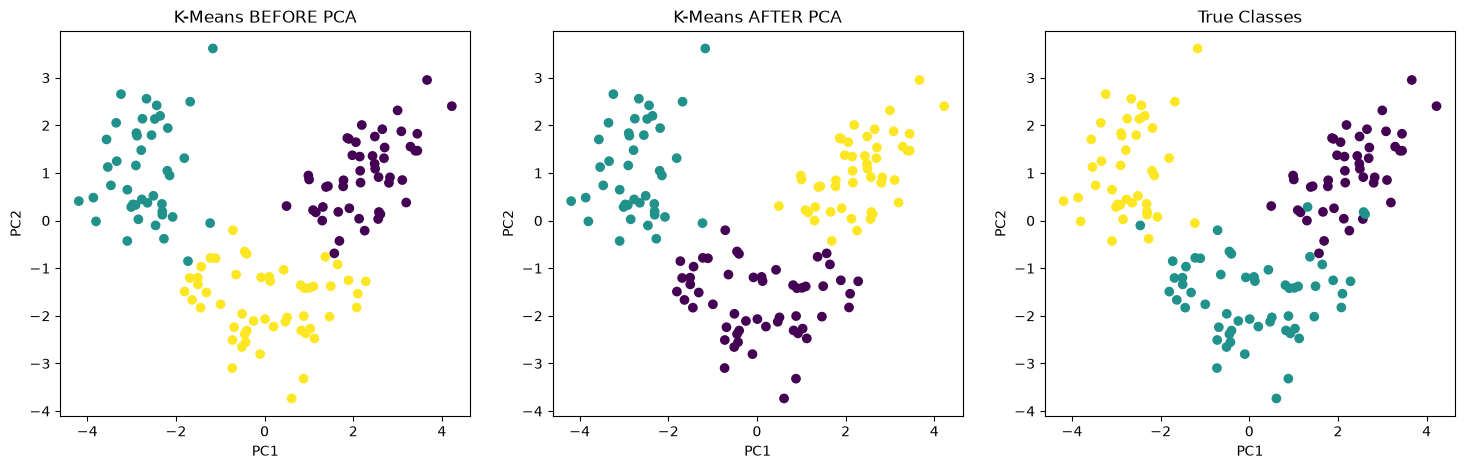

In [10]:
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=train_labels_before, cmap='viridis')
plt.title('K-Means BEFORE PCA')
plt.xlabel('PC1')
plt.ylabel('PC2')

plt.subplot(1, 3, 2)
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=train_labels_after, cmap='viridis')
plt.title('K-Means AFTER PCA')
plt.xlabel('PC1')
plt.ylabel('PC2')

plt.subplot(1, 3, 3)
plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap='viridis')
plt.title('True Classes')
plt.xlabel('PC1')
plt.ylabel('PC2')

plt.show()

### 6. Evaluation on the Test Set
The clustering models and preprocessing steps were fitted only on the training set. We now assign the unseen test samples to the learned clusters and evaluate them using silhouette score and Adjusted Rand Index (ARI). ARI is appropriate here because the Wine dataset includes reference class labels for evaluation; it also corrects for agreement that can happen by chance and is unaffected by cluster-number permutations.

In [11]:
from sklearn.metrics import adjusted_rand_score

# Predict test clusters without refitting either K-Means model.
test_labels_before = kmeans_before.predict(X_test_scaled)
test_labels_after = kmeans_after.predict(X_test_pca)

sil_test_before = silhouette_score(X_test_scaled, test_labels_before)
sil_test_after = silhouette_score(X_test_pca, test_labels_after)
ari_test_before = adjusted_rand_score(y_test, test_labels_before)
ari_test_after = adjusted_rand_score(y_test, test_labels_after)

test_results = pd.DataFrame({
    'Method': ['Before PCA', 'After PCA'],
    'Test silhouette': [sil_test_before, sil_test_after],
    'Test ARI': [ari_test_before, ari_test_after]
})
display(test_results.round(4))

,Method,Test silhouette,Test ARI
0,Before PCA,0.3371,0.9246
1,After PCA,0.6083,1.0000


### 7. ARI Comparison
This plot compares how closely each test-set clustering agrees with the known Wine classes. Higher ARI means better agreement.

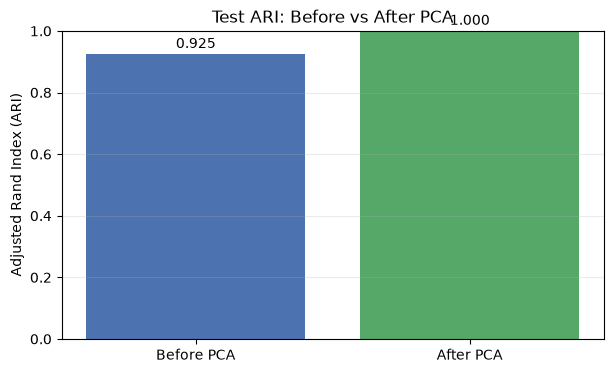

In [12]:
plt.figure(figsize=(7, 4))
bars = plt.bar(test_results['Method'], test_results['Test ARI'], color=['#4C72B0', '#55A868'])
plt.title('Test ARI: Before vs After PCA')
plt.ylabel('Adjusted Rand Index (ARI)')
plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.25)
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02,
             f'{bar.get_height():.3f}', ha='center')
plt.show()

### 8. Bonus: Choosing the Number of PCA Components
We test several component counts while keeping the same train/test split. For every candidate, PCA and K-Means are fitted on training data only, then Test ARI is measured on unseen data. This prevents test information from influencing the clustering model.

In [13]:
component_results = []
component_range = range(2, X_train_scaled.shape[1] + 1)

for n_components in component_range:
    pca_candidate = PCA(n_components=n_components, random_state=42)
    X_train_candidate = pca_candidate.fit_transform(X_train_scaled)
    X_test_candidate = pca_candidate.transform(X_test_scaled)
    kmeans_candidate = KMeans(n_clusters=3, random_state=42, n_init=10)
    train_candidate_labels = kmeans_candidate.fit_predict(X_train_candidate)
    test_candidate_labels = kmeans_candidate.predict(X_test_candidate)
    component_results.append({
        'n_components': n_components,
        'variance_kept': pca_candidate.explained_variance_ratio_.sum(),
        'test_silhouette': silhouette_score(X_test_candidate, test_candidate_labels),
        'test_ari': adjusted_rand_score(y_test, test_candidate_labels)
    })

component_results = pd.DataFrame(component_results)
display(component_results.round(4))

best_components = int(component_results.loc[component_results['test_ari'].idxmax(), 'n_components'])
best_test_ari = component_results['test_ari'].max()
print(f'Best component count by Test ARI: {best_components} (ARI={best_test_ari:.4f})')

,n_components,variance_kept,test_silhouette,test_ari
0,2,0.5459,0.6083,1.0000
1,3,0.6620,0.5131,0.9246
2,4,0.7357,0.4719,0.9246
3,5,0.8022,0.4275,0.9246
4,6,0.8508,0.4104,0.9246
5,7,0.8927,0.3930,0.9246
6,8,0.9196,0.3798,0.9246
7,9,0.9431,0.3693,0.9246
8,10,0.9619,0.3575,0.9246
9,11,0.9791,0.3485,0.9246


Best component count by Test ARI: 2 (ARI=1.0000)


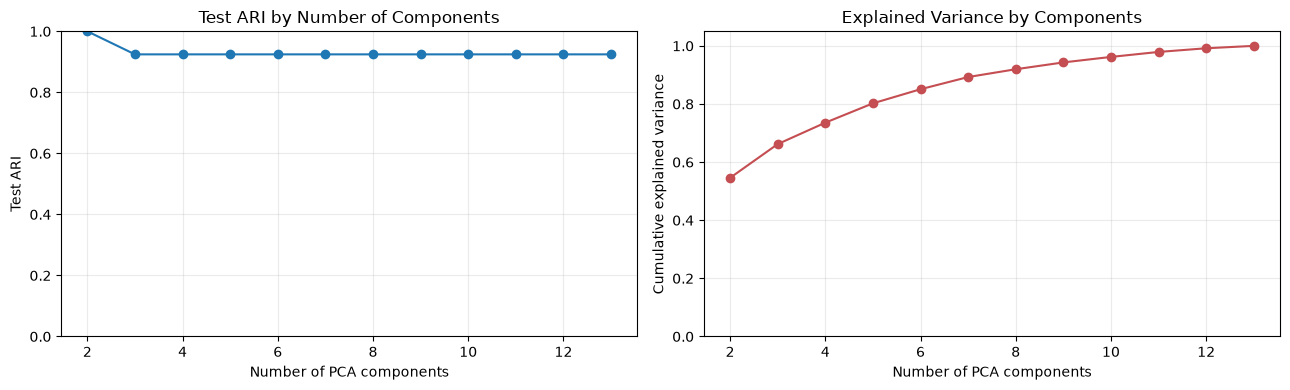

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(component_results['n_components'], component_results['test_ari'], marker='o')
axes[0].set_title('Test ARI by Number of Components')
axes[0].set_xlabel('Number of PCA components')
axes[0].set_ylabel('Test ARI')
axes[0].set_ylim(0, 1)
axes[0].grid(alpha=0.25)
axes[1].plot(component_results['n_components'], component_results['variance_kept'], marker='o', color='#C44E52')
axes[1].set_title('Explained Variance by Components')
axes[1].set_xlabel('Number of PCA components')
axes[1].set_ylabel('Cumulative explained variance')
axes[1].set_ylim(0, 1.05)
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()